In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We propose a novel approach to learning from n...,0.3137,0.0724,0.1765,0.8596,0.8156,0.8370,2,8,8,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,"In this paper, we propose a novel 3D convoluti...",0.3242,0.1050,0.1978,0.8630,0.8274,0.8448,3,9,8,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,This paper presents a survey of the literature...,0.3273,0.0859,0.1939,0.8845,0.8599,0.8721,4,9,8,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


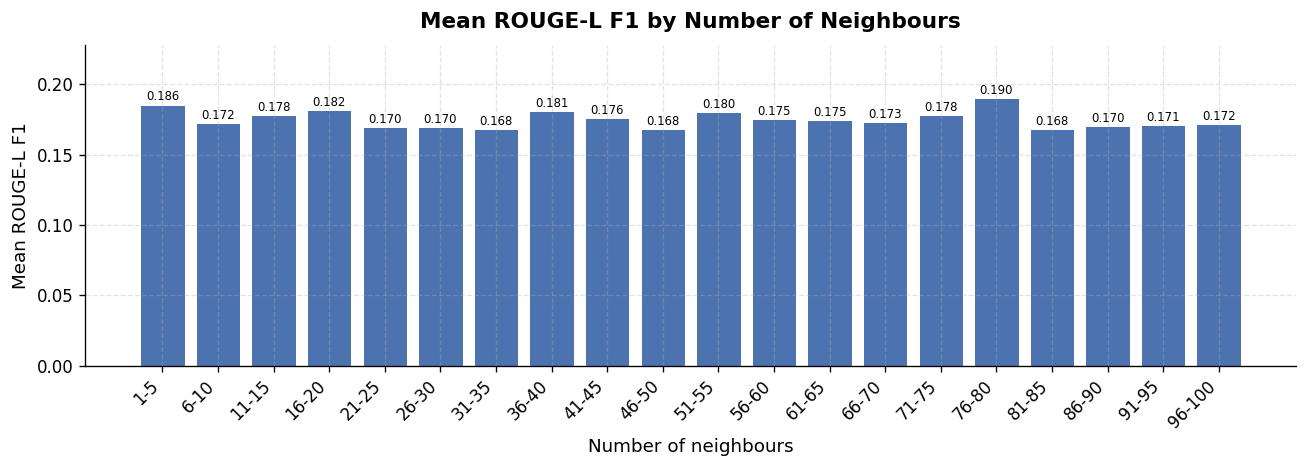

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

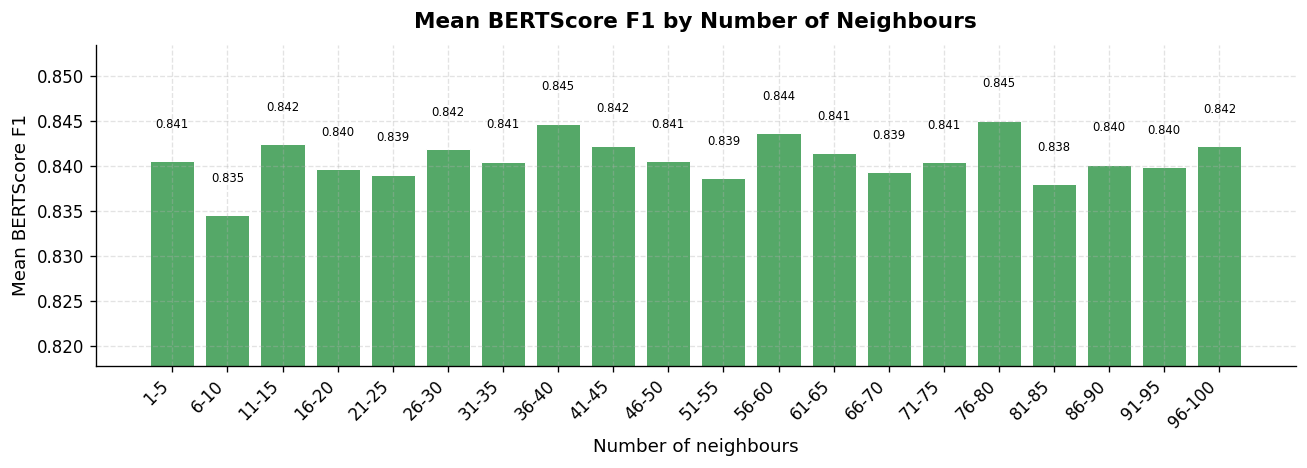

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

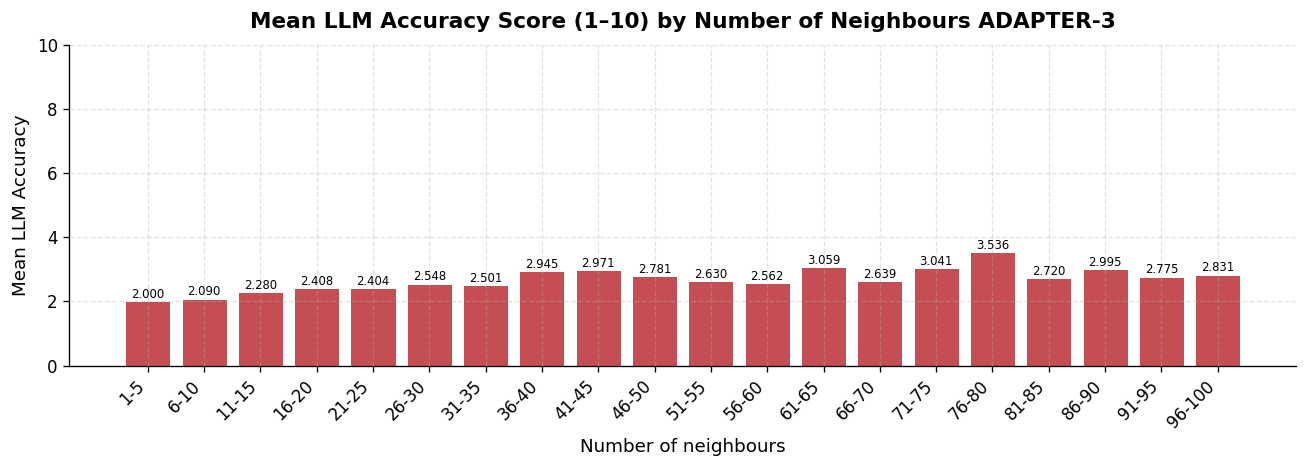

2.712169312169312
2.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

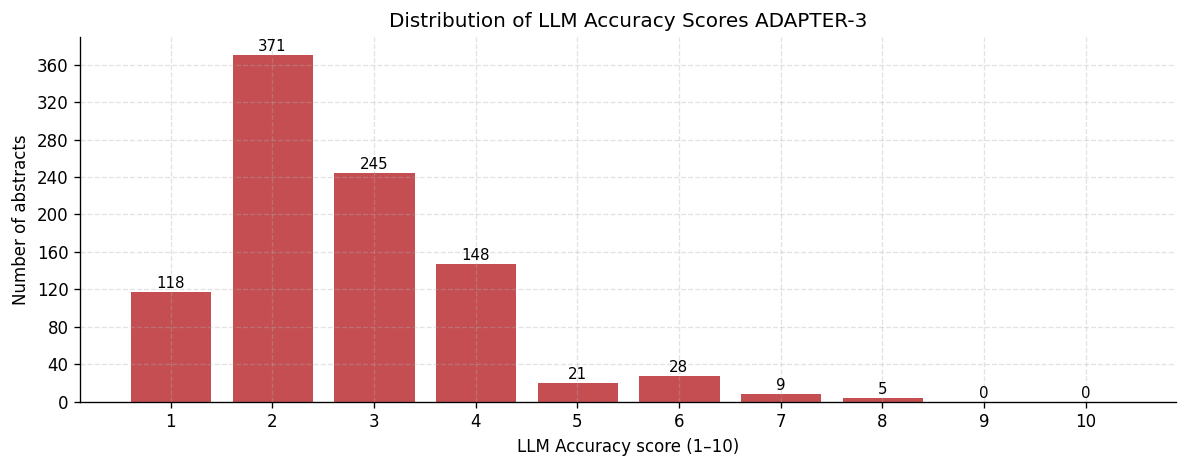

llm_accuracy
1     118
2     371
3     245
4     148
5      21
6      28
7       9
8       5
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

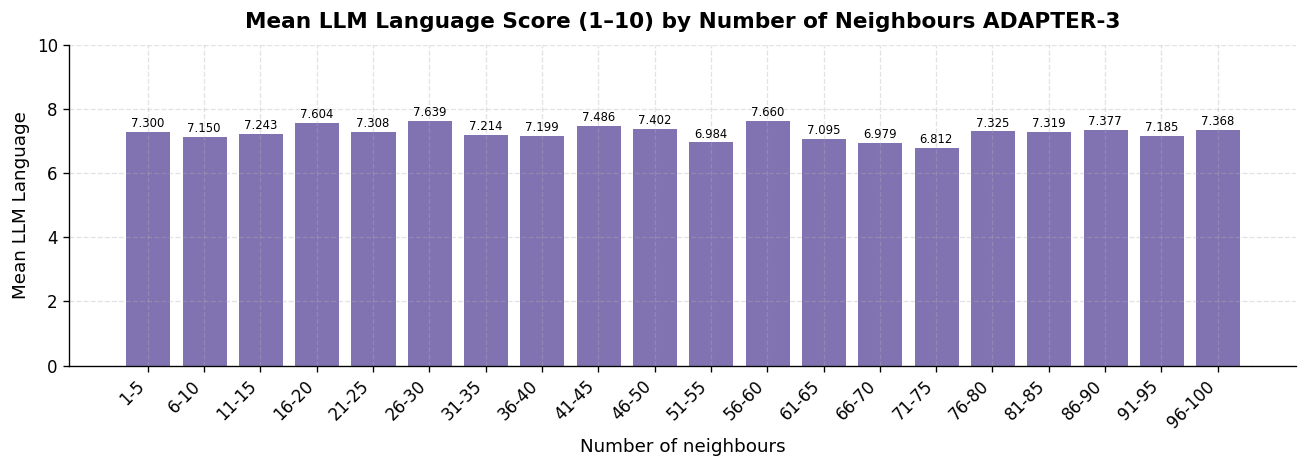

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

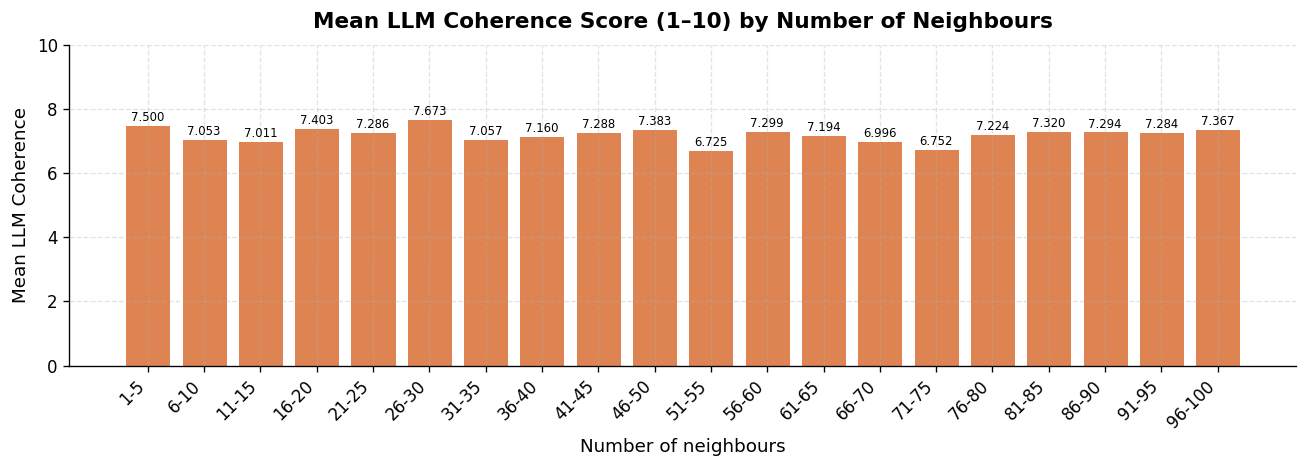

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

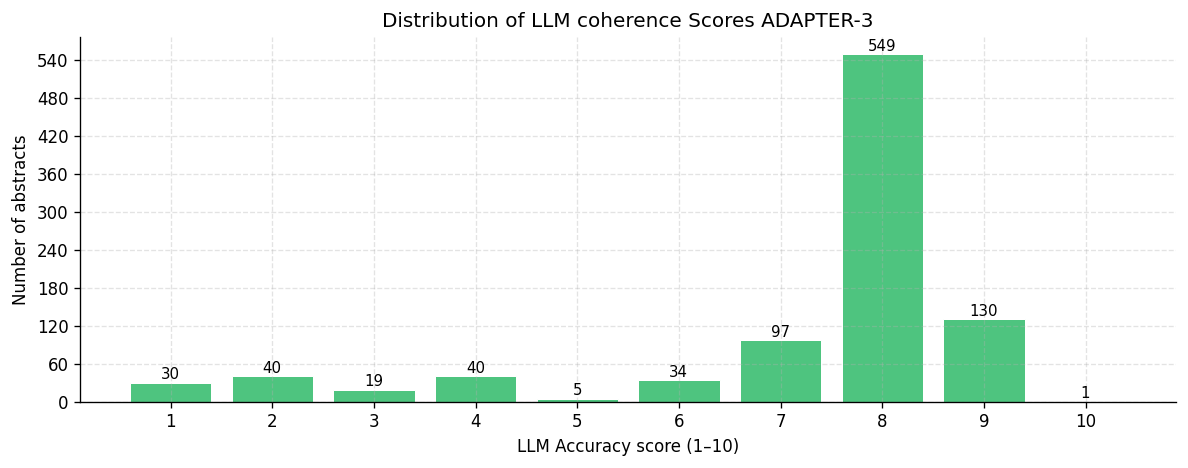

llm_coherence
1      30
2      40
3      19
4      40
5       5
6      34
7      97
8     549
9     130
10      1
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 70 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      2.7122
Mean llm_accuracy (excluding 1,2): 2.7806


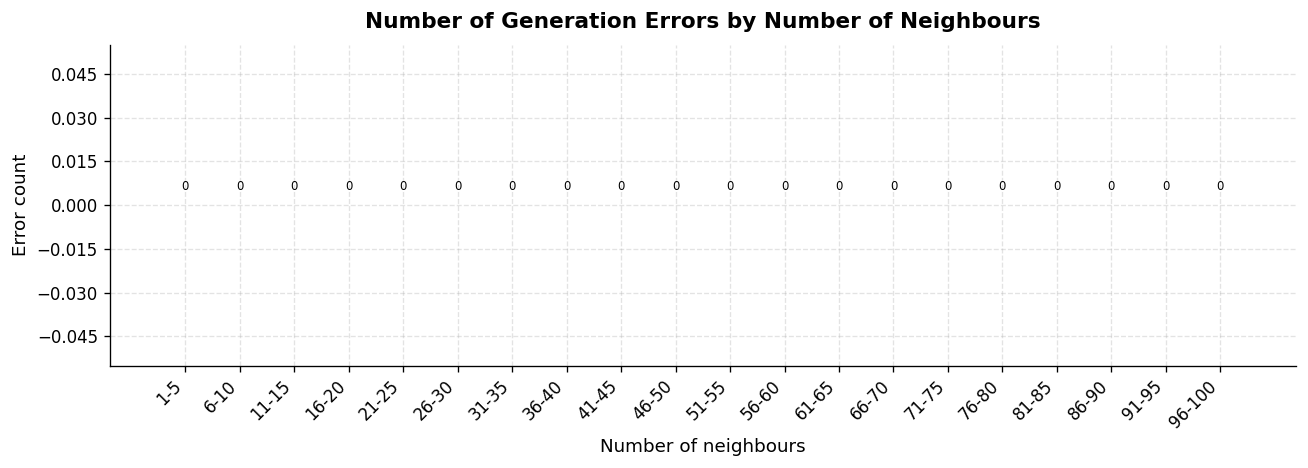

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_86570/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,87146,"Issue tracking systems are commonly used in modern software development for collecting feedback from users and developers. An ultimate automation target of software maintenance is then the systematization of patch generation for user-reported bugs. Although this ambition is aligned with the momentum of automated program repair, the literature has, so far, mostly focused on generate-and- validate setups where fault localization and patch generation are driven by a well-defined test suite. On the one hand, however, the common (yet strong) assumption on the existence of relevant test cases does not hold in practice for most development settings: many bugs are reported without the available test suite being able to reveal them. On the other hand, for many projects, the number of bug reports generally outstrips the resources available to triage them. Towards increasing the adoption of patch generation tools by practitioners, we investigate a new repair pipeline, iFixR, driven by bug reports: (1) bug reports are fed to an IR-based fault localizer; (2) patches are generated from fix patterns and validated via regression testing; (3) a prioritized list of generated patches is proposed to developers. We evaluate iFixR on the Defects4J dataset, which we enriched (i.e., faults are linked to bug reports) and carefully-reorganized (i.e., the timeline of test-cases is naturally split). iFixR generates genuine/plausible patches for 21/44 Defects4J faults with its IR-based fault localizer. iFixR accurately places a genuine/plausible patch among its top-5 recommendation for 8/13 of these faults (without using future test cases in generation-and-validation).",The increasing complexity of software systems has led to a growing number of defects in software. The defects are often reported by users and developers as bug reports. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs) such as Bugzilla and Jira. The bug reports are usually submitted to bug tracking systems (BTSs,1
1,70276,"With the prevalence of RGB-D cameras, multi-modal video data have become more available for human action recognition. One main challenge for this task lies in how to effectively leverage their complementary information. In this work, we propose a Modality Compensation Network (MCN) to explore the relationships of different modalities, and boost the representations for human action recognition. We regard RGB/optical flow videos as source modalities, skeletons as auxiliary modality. Our goal is to extract more discriminative features from source modalities, with the help of auxiliary modality. Built on deep Convolutional Neural Networks (CNN) and Long Short Term Memory (LSTM) networks, our model bridges data from source and auxiliary modalities by a modality adaptation block to achieve adaptive representation learning, that the network learns to compe

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_86570/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,118427,"In this work, we consider the almost-sure termination problem for probabilistic programs that asks whether a given probabilistic program terminates with probability 1. Scalable approaches for program analysis often rely on compositional analysis as their theoretical basis. In non-probabilistic programs, the classical variant rule (V-rule) of Floyd-Hoare logic is the foundation for compositional analysis. Extension of this rule to almost-sure termination of probabilistic programs is quite tricky, and a probabilistic variant was proposed in [15]. While the proposed probabilistic variant cautiously addresses the key issue of integrability, we show that the proposed compositional rule is still not sound for almost-sure termination of probabilistic programs. Besides establishing unsoundness of the previous rule, our contributions are as follows: First, we present a sound compositional rule for almost-sure termination of probabilistic programs. Our approach is based on a novel notion of descent supermartingales. Second, for algorithmic approaches, we consider descent supermartingales that are linear and show that they can be synthesized in polynomial time. Finally, we present experimental results on several natural examples that model various types of nested while loops in probabilistic programs and demonstrate that our approach is able to efficiently prove their almost-sure termination property.","We study the complexity of model checking for the branching-time temporal logic CTL* and its fragments. We show that the model checking problem for CTL* is PSPACE-complete for all classes of Kripke structures with at most k states, for every k ≥ 2. We also show that the model checking problem for the fragment of CTL* that includes all path quantifiers is PSPACE-complete for all classes of Kripke structures with at most k states, for every k ≥ 2. We then show that the model checking problem for the fragment of CTL* that includes all branching-time operators is PSPACE-complete for all classes of Kripke structures with at most k states, for every k ≥ 2. We also show that the model checking problem for the fragment of CTL* that includes all branching-time operators and the existential path quantifier is PSPACE-complete for all classes of Kripke structures with at most k states, for every k ≥ 2.",1
1,127698,"Online advertising has been a long-standing concern for user privacy and overall web experience. Several techniques have been proposed to block ads, mostly based on filter-lists and manually-written rules. While a typical ad blocker relies on manually-curated block lists, these inevitably get out-of-date, thus compromising the ultimate utility of this ad blocking approach. In this paper we present Percival, a browser-embedded, lightweight, deep learning-powered ad blocker. Percival embeds itself within the browser's image rendering pipeline, which makes it possible to intercept every image obtained during page execution and to perform blocking based on applying machine learning for image classification to flag potential ads. Our implementation inside both Chromium and Brave browsers shows only a minor rendering performance overhead of 4.55%, demonstrating the feasibility of deploying traditionally heavy models (i.e. deep neural networks) inside the critical path of the rendering engine of a browser. We show that our image-based ad blocker can replicate EasyList rules with an accuracy of 96.76%. To show the versatility of the Percival's approach we present case studies that demonstrate that Percival 1) does surprisingly well on ads in languages other than English; 2) Percival also performs well on blocking first-party Facebook ads, which have presented issues for other ad blockers. Percival proves that image-based perceptual ad blocking is an attractive complement to today's dominant approach of block lists","We present a system for detecting malware in Android apps. Our s

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


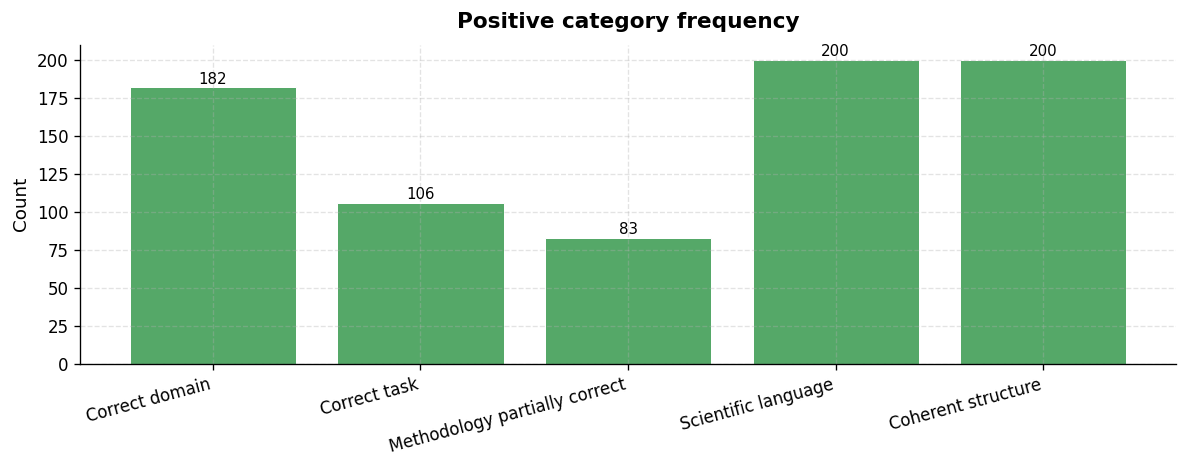

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()